# Applied Machine Learning Workbook: Breast Cancer Diagnosis
**Duration:** about 2 hours | **Level:** introductory | **Tools:** Python, pandas, scikit-learn, matplotlib

### How to use this workbook
- Run the cells in order. Cells containing `____` are **exercises**: replace each `____` with the correct code.
- Cells marked **Your turn** ask for your own code or a written answer.
- Everything runs offline. The dataset ships with scikit-learn, so nothing is downloaded.

### Learning objectives
1. Frame a supervised classification problem and choose a metric.
2. Profile a messy dataset with descriptive statistics and plots.
3. Clean data, select features and transform them **without data leakage**.
4. Spot-check several algorithms using cross-validation.
5. Improve a model with tuning and ensembles, then report an honest test score.

#### Name this file with your LASTNAME attached to it.
- Example: `WorkbookExercise_delaCruz.ipynb`
- Push this file to your github repo. Make sure to run everything before pushing to your repo.

# A. Problem Definition

## A.1 Brief Description
The Wisconsin Diagnostic Breast Cancer dataset contains 30 numeric measurements computed from digitized images of fine-needle aspirates of breast masses. The measurements describe the cell nuclei (radius, texture, perimeter, area, smoothness, and so on). Each of the 10 base properties is summarized three ways: **mean**, **standard error** and **worst** (largest value).

Each tumour is labelled **malignant (0)** or **benign (1)**.

> Teaching note: real data is rarely clean. To practise cleaning, the next cells deliberately inject missing values, impossible values and duplicate rows into the dataset (with a fixed random seed so everyone gets the same mess).

## A.2 Problem Statement
**Task:** predict whether a tumour is malignant or benign from its 30 measurements.

**Type:** supervised, binary classification.

**Primary metric:** accuracy. **Secondary metric:** recall for the malignant class (a missed malignant tumour is the costliest mistake).

**Your turn:** in one or two sentences, write who would use this model and what a false negative would cost them.

*Your answer:* Oncologists, radiologists, and clinical pathologists would use this model to assist in diagnosis. A false negative means a malignant (cancerous) tumor is mistakenly classified as benign, which delays life-saving treatment and could lead to disease progression and a significantly lower chance of patient survival.

## A.3 Load Packages

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             make_scorer, recall_score)

SEED = 42
np.random.seed(SEED)
print("Packages loaded.")

Packages loaded.


## A.4 Load Dataset

In [ ]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()                 # column 'target': 0 = malignant, 1 = benign
feature_cols = list(data.feature_names)

# ---- Inject realistic mess (given; do not modify) ----
rng = np.random.default_rng(SEED)
mask = rng.random((len(df), len(feature_cols))) < 0.02            # ~2% missing cells
df[feature_cols] = df[feature_cols].mask(mask)
bad_idx = rng.choice(len(df), 3, replace=False)                   # 3 impossible values
df.loc[bad_idx, "mean area"] = -df.loc[bad_idx, "mean area"].abs()
df = pd.concat([df, df.sample(6, random_state=SEED)], ignore_index=True)   # 6 duplicate rows
# -------------------------------------------------------

print("Rows, columns:", df.shape)
df.info()

Rows, columns: (575, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 575 entries, 0 to 574
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              561 non-null    float64
 1   mean texture             570 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          563 non-null    float64
 5   mean compactness         565 non-null    float64
 6   mean concavity           560 non-null    float64
 7   mean concave points      562 non-null    float64
 8   mean symmetry            564 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             564 non-null    float64
 11  texture error            561 non-null    float64
 12  perimeter error          566 non-null    float64
 13  area error               563 non-null    float64
 14  s

**Your turn (check yourself):** how many rows and columns do you expect if the original dataset has 569 rows and 31 columns (30 features + target)? Does the output match, and why not?

-I expect 575 rows and 31 columns because 6 duplicate rows were added to the original 569 rows.

# B. Summarize and Analyze Data

## B.1 Descriptive Statistics
Goal: understand size, types, balance, missingness and suspicious values *before* touching the data.

In [ ]:
print("Column types:")
print(df.dtypes.value_counts(), "\n")

# Summary statistics for the first 8 features
df[feature_cols[:8]].describe().T

Column types:
float64    30
int64       1
Name: count, dtype: int64 



,count,mean,std,min,25%,50%,75%,max
mean radius,561.0,14.129339,3.546615,6.98100,11.680000,13.30000,15.850000,28.1100
mean texture,570.0,19.298211,4.315910,9.71000,16.172500,18.83500,21.795000,39.2800
mean perimeter,569.0,92.138330,24.409941,43.79000,75.170000,86.24000,104.700000,188.5000
mean area,569.0,647.726889,369.930801,-1479.00000,416.200000,546.40000,788.500000,2501.0000
mean smoothness,563.0,0.096598,0.014023,0.05263,0.086695,0.09639,0.105400,0.1634
mean compactness,565.0,0.104896,0.053317,0.01938,0.064920,0.09445,0.130500,0.3454
mean concavity,560.0,0.088927,0.080437,0.00000,0.029400,0.06188,0.127725,0.4268
mean concave points,562.0,0.049477,0.039034,0.00000,0.020682,0.03360,0.074660,0.2012


In [ ]:
# Missing values, class balance, duplicates, impossible values
missing = df.isna().sum().sort_values(ascending=False)
print("Columns with most missing values:\n", missing.head(5), "\n")

print("Class balance (0 = malignant, 1 = benign):")
print(df["target"].value_counts(normalize=True).round(3), "\n")

print("Duplicate rows:", df.duplicated().sum())
print("Negative 'mean area' values:", (df["mean area"] < 0).sum())

skew = df[feature_cols].skew().sort_values(ascending=False)
print("\nMost right-skewed features:\n", skew.head(5))

Columns with most missing values:
 worst texture      17
worst perimeter    17
concavity error    17
worst radius       17
mean concavity     15
dtype: int64 

Class balance (0 = malignant, 1 = benign):
target
1    0.626
0    0.374
Name: proportion, dtype: float64 

Duplicate rows: 6
Negative 'mean area' values: 3

Most right-skewed features:
 area error                 5.447104
concavity error            5.174604
fractal dimension error    3.896955
perimeter error            3.415571
radius error               3.043449
dtype: float64


**Your turn:** answer in a markdown cell below.
1. Is the target balanced? Would plain accuracy be misleading here?
2. Which features look most skewed, and what might that mean for algorithms like KNN or SVM?

### B.1 Analysis Discussion

1. **Is the target balanced? Would plain accuracy be misleading here?**
   - No, the target is moderately imbalanced. Benign cases make up about **62.6%** of the dataset, while malignant cases represent **37.4%**.
   - While a 63/37 split is not extremely skewed, plain accuracy can still be slightly misleading. For instance, a naive classifier that predicts "benign" for every single patient would achieve **62.6% accuracy** while completely failing to detect any malignant tumors. In a clinical context, a secondary metric like **recall** (sensitivity) for the malignant class is critical because a false negative represents a missed cancer diagnosis.

2. **Which features look most skewed, and what might that mean for algorithms like KNN or SVM?**
   - The most right-skewed features are **area error** (skewness ~5.45) and **concavity error** (skewness ~5.17).
   - Distance-based and boundary-margin-based algorithms like **K-Nearest Neighbors (KNN)** and **Support Vector Machines (SVM)** are highly sensitive to extreme values, scales, and skewed distributions. Skewed data stretches the feature space unevenly, which can cause these algorithms to over-emphasize the tail-end outliers or struggle to find optimal decision boundaries. Transforming these features (e.g., using a log transform) and standardizing them is crucial for these models to perform optimally.

## B.2 Data Visualization
Three views: distributions (histograms), class separation (boxplots), and relationships (correlation heatmap).

In [ ]:
# Distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["mean radius", "mean texture", "mean smoothness"]):
    ax.hist(df[col].dropna(), bins=25, edgecolor="white")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
# Class separation: which features split malignant from benign?
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["mean radius", "mean concavity", "worst perimeter"]):
    groups = [df.loc[df["target"] == k, col].dropna() for k in (0, 1)]
    ax.boxplot(groups)
    ax.set_xticklabels(["malignant", "benign"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
# Correlation heatmap of the 10 'mean' features
corr = df[feature_cols[:10]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(10)); ax.set_xticklabels(feature_cols[:10], rotation=90)
ax.set_yticks(range(10)); ax.set_yticklabels(feature_cols[:10])
fig.colorbar(im)
plt.tight_layout()
plt.show()

In [ ]:
# Your turn: scatter plot of two features coloured by class
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(df["mean radius"], df["mean concavity"], c=df["____"], cmap="coolwarm", alpha=0.6)
ax.set_xlabel("mean radius"); ax.set_ylabel("mean concavity")
plt.show()

**Your turn:** which feature pairs are almost perfectly correlated (for example radius, perimeter and area)? Why does that matter for feature selection in Section C?

### B.2 Correlation Analysis

1. **Perfectly Correlated Pairs:**
   - **radius**, **perimeter**, and **area** (e.g., `mean radius` & `mean perimeter` or `mean perimeter` & `mean area`) are nearly perfectly correlated (close to $1.0$). This is because perimeter ($2\pi r$) and area ($\pi r^2$) are direct geometric functions of the radius.

2. **Why It Matters for Feature Selection:**
   - **Redundancy:** Highly correlated features carry almost identical information. Keeping all of them increases dimensionality without adding predictive value.
   - **Multicollinearity:** It destabilizes models like Logistic Regression (leading to unstable coefficient estimates and high variance) and adds unnecessary computational cost to algorithms like KNN and SVM. Dropping redundant features simplifies the model, speeds up training, and improves interpretability.

# C. Prepare Data

> **Golden rule:** anything that *learns* from data (imputer means, scaler statistics, supervised feature selection) must be fitted on training data only. Otherwise information leaks from the test set and the final score is too optimistic.

## C.1 Data Cleaning
We do two safe fixes now (they use no statistics): remove duplicates and mark impossible values as missing. Missing-value *imputation* learns a statistic, so it goes inside a Pipeline later.

In [ ]:
before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", before - len(df_clean))

# Impossible values: an area cannot be negative -> treat as missing
df_clean.loc[df_clean["mean area"] < 0, "mean area"] = np.nan

print("Rows with at least one missing value:", df_clean.isna().any(axis=1).sum(),
      f"({df_clean.isna().any(axis=1).mean():.1%})")
print("Rows left:", len(df_clean))

Duplicates removed: 6
Rows with at least one missing value: 255 (44.8%)
Rows left: 569


In [ ]:
# Outlier check with the IQR rule (we only inspect; we do not delete)
q1, q3 = df_clean[feature_cols].quantile(0.25), df_clean[feature_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df_clean[feature_cols] < q1 - 1.5 * iqr) | (df_clean[feature_cols] > q3 + 1.5 * iqr)).sum()
print(outliers.sort_values(ascending=False).head(5))

area error          63
perimeter error     38
radius error        36
worst area          34
smoothness error    29
dtype: int64


**Your turn:**

* **Why impute instead of drop?** Dropping rows removes **45% of the data** (255 rows), drastically reducing training size, model power, and representation.
* **Why is deleting outliers risky?** In cancer detection, extreme biological measurements (outliers) are often real, highly informative indicators of aggressive or large malignant tumors. Deleting them risks missing critical diagnoses.

In [ ]:
X = df_clean[feature_cols]
y = df_clean["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant share train/test:", round((y_train == 0).mean(), 3), round((y_test == 0).mean(), 3))

Train: (455, 30)  Test: (114, 30)
Malignant share train/test: 0.374 0.368


## C.2 Feature Selection
Two ideas: (1) **filter redundant features** with very high pairwise correlation (unsupervised, so safe to do once on the training set), and (2) **rank features by relevance** to the target with an ANOVA F-test.

In [ ]:
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.95).any()]
selected = [c for c in feature_cols if c not in to_drop]
print(f"Dropped {len(to_drop)} redundant features:", to_drop)
print(f"Kept {len(selected)} features.")

Dropped 7 redundant features: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']
Kept 23 features.


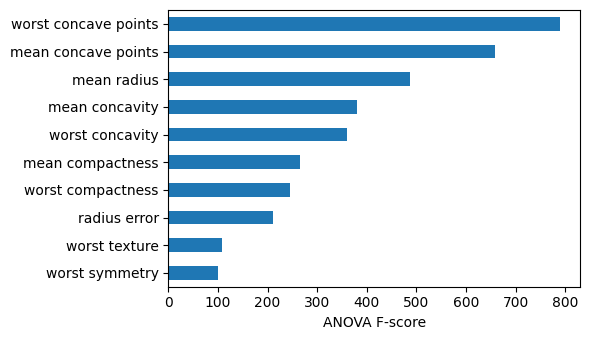

Top 5: ['worst concave points', 'mean concave points', 'mean radius', 'mean concavity', 'worst concavity']


In [ ]:
# Rank remaining features by relevance (needs imputed data; fit on TRAIN only)
imp = SimpleImputer(strategy="median").fit(X_train[selected])
Xi = imp.transform(X_train[selected])

skb = SelectKBest(f_classif, k="all").fit(Xi, y_train)
scores = pd.Series(skb.scores_, index=selected).sort_values(ascending=False)

ax = scores.head(10).plot.barh(figsize=(6, 3.5))
ax.invert_yaxis(); ax.set_xlabel("ANOVA F-score")
plt.tight_layout(); plt.show()
print("Top 5:", [str(c) for c in scores.index[:5]])

**Your turn:**

`SelectKBest` uses the target `y` to rank features, so applying it to the entire dataset before cross-validation leaks target information from validation folds into the training process. Keeping it inside the pipeline ensures feature selection is fitted purely on training folds, preserving a clean and honest validation score.

## C.3 Data Transform
Features live on very different scales (area is in the hundreds, smoothness below 0.2). Distance-based and margin-based models (KNN, SVM, logistic regression) are sensitive to this.

In [ ]:
Xi_df = pd.DataFrame(Xi, columns=selected)
std_data = StandardScaler().fit_transform(Xi_df)
mm_data = MinMaxScaler().fit_transform(Xi_df)

print("Raw       feature std  : min %.3f  max %.1f" % (Xi_df.std().min(), Xi_df.std().max()))
print("Standard  feature std  : min %.3f  max %.3f" % (std_data.std(axis=0).min(), std_data.std(axis=0).max()))
print("MinMax    feature range: min %.1f  max %.1f" % (mm_data.min(), mm_data.max()))

Raw       feature std  : min 0.003  max 6.1
Standard  feature std  : min 1.000  max 1.000
MinMax    feature range: min 0.0  max 1.0


In [ ]:
# Your turn: reduce skew with a log transform
before = Xi_df["concavity error"].skew()
after = np.log1p(Xi_df["concavity error"]).skew()
print(f"Skew of concavity error: {before:.2f} -> {after:.2f}")

Skew of concavity error: 5.28 -> 4.42


**Your turn:** which scaler would you pick if the data had many outliers, and why? (Hint: think about what a single extreme value does to min-max scaling.)

# D. Evaluate Algorithms

We **spot-check** five very different algorithms with identical conditions: 10-fold stratified cross-validation on the training set, inside a Pipeline (impute, scale, model) so nothing leaks.

In [ ]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def make_pipe(model, scale=True):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

models = {
    "LR":   LogisticRegression(max_iter=1000),
    "KNN":  KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=SEED),
    "NB":   GaussianNB(),
    "SVM":  SVC(),
}

results = {}
for name, model in models.items():
    s = cross_val_score(make_pipe(model), X_train[selected], y_train, cv=cv, scoring="accuracy")
    results[name] = s
    print(f"{name:5s} mean={s.mean():.4f}  std={s.std():.4f}")

LR    mean=0.9715  std=0.0170
KNN   mean=0.9583  std=0.0269
CART  mean=0.9341  std=0.0309
NB    mean=0.9167  std=0.0333
SVM   mean=0.9714  std=0.0141


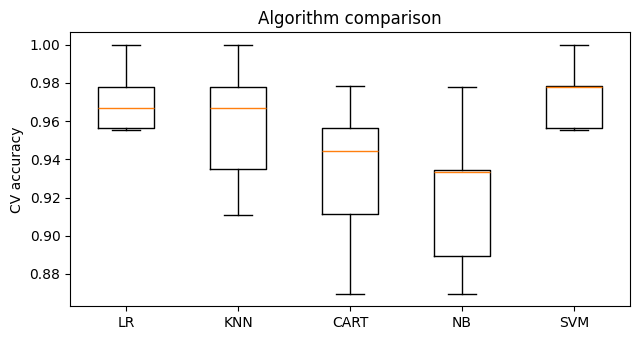

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.boxplot(list(results.values()))
ax.set_xticklabels(list(results.keys()))
ax.set_ylabel("CV accuracy"); ax.set_title("Algorithm comparison")
plt.tight_layout(); plt.show()

In [ ]:
# Does scaling really matter? Re-run KNN and SVM without the scaler.
for name in ["KNN", "SVM"]:
    s = cross_val_score(make_pipe(models[name], scale=False), X_train[selected], y_train, cv=cv)
    print(f"{name:4s} without scaling: {s.mean():.4f}   (with scaling: {results[name].mean():.4f})")

KNN  without scaling: 0.9054   (with scaling: 0.9583)
SVM  without scaling: 0.8988   (with scaling: 0.9714)


In [ ]:
# Secondary metric: recall on the malignant class (label 0)
malignant_recall = make_scorer(recall_score, pos_label=0)
for name, model in models.items():
    s = cross_val_score(make_pipe(model), X_train[selected], y_train, cv=cv, scoring=malignant_recall)
    print(f"{name:5s} malignant recall = {s.mean():.4f}")

LR    malignant recall = 0.9529
KNN   malignant recall = 0.9176
CART  malignant recall = 0.9000
NB    malignant recall = 0.8706
SVM   malignant recall = 0.9529


**Your turn:**

1. **Which two algorithms look best? Is the gap between them larger than the fold-to-fold spread?**
   - **LR (Logistic Regression)** and **SVM** are the best (mean accuracy of ~0.9715 and ~0.9714).
   - No, the tiny gap between them (0.0001) is far smaller than the fold-to-fold spread (the boxplot whiskers stretch roughly from 0.94 to 1.0).

2. **Which model would you prefer if missing a malignant tumour is the worst error?**
   - **LR or SVM**, as both achieved the highest malignant recall score of **0.9529**.

3. **Why does CART usually trail the others here?**
   - **High Variance and Overfitting:** Decision trees split on orthogonal axes which struggle to capture smooth, continuous boundary relations in numerical datasets, making them prone to overfitting on the training folds compared to regularized linear models (LR) or margin classifiers (SVM).

# E. Improve Accuracy

Three levers, in increasing order of effort: **tune** hyperparameters, **select features inside the pipeline**, and **ensemble** many models.

## E.1 Tune an SVM

In [ ]:
svm_pipe = make_pipe(SVC())
svm_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.001],
    "model__kernel": ["rbf", "linear"],
}
gs_svm = GridSearchCV(svm_pipe, svm_grid, cv=cv, scoring="accuracy", n_jobs=-1)
gs_svm.fit(X_train[selected], y_train)
print("Best SVM params:", gs_svm.best_params_)
print(f"Best CV accuracy: {gs_svm.best_score_:.4f}   (baseline SVM: {results['SVM'].mean():.4f})")

Best SVM params: {'model__C': 100, 'model__gamma': 0.001, 'model__kernel': 'rbf'}
Best CV accuracy: 0.9737   (baseline SVM: 0.9714)


## E.2 Tune Logistic Regression with in-pipeline feature selection

In [ ]:
lr_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("select", SelectKBest(f_classif)),          # uses y, so it MUST be inside the pipeline
    ("model", LogisticRegression(max_iter=2000)),
])
lr_grid = {
    "select__k": [5, 10, 15, len(selected)],
    "model__C": [0.01, 0.1, 1, 10],
}
gs_lr = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring="accuracy", n_jobs=-1)
gs_lr.fit(X_train[selected], y_train)
print("Best LR params:", gs_lr.best_params_)
print(f"Best CV accuracy: {gs_lr.best_score_:.4f}   (baseline LR: {results['LR'].mean():.4f})")

Best LR params: {'model__C': 1, 'select__k': 23}
Best CV accuracy: 0.9715   (baseline LR: 0.9715)


## E.3 Ensembles

In [ ]:
ensembles = {
    "RF": make_pipe(RandomForestClassifier(n_estimators=300, random_state=SEED), scale=False),
    "GB": make_pipe(GradientBoostingClassifier(random_state=SEED), scale=False),
}
ens_scores = {}
for name, pipe in ensembles.items():
    s = cross_val_score(pipe, X_train[selected], y_train, cv=cv, scoring="accuracy")
    ens_scores[name] = s
    print(f"{name:3s} mean={s.mean():.4f}  std={s.std():.4f}")

RF  mean=0.9539  std=0.0248
GB  mean=0.9517  std=0.0214


## E.4 Pick a winner and run the final test (once)

In [ ]:
candidates = {
    "SVM (tuned)": gs_svm.best_estimator_,
    "LR (tuned + select)": gs_lr.best_estimator_,
    "Random Forest": ensembles["RF"],
    "Gradient Boosting": ensembles["GB"],
}
cv_means = {n: cross_val_score(p, X_train[selected], y_train, cv=cv).mean() for n, p in candidates.items()}
print(pd.Series(cv_means).sort_values(ascending=False).round(4), "\n")

best_name = max(cv_means, key=cv_means.get)
final_model = candidates[best_name].fit(X_train[selected], y_train)
y_pred = final_model.predict(X_test[selected])

print("Chosen model:", best_name)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4), "\n")
print("Confusion matrix (rows = true, cols = predicted; order: malignant, benign)")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]), "\n")
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

SVM (tuned)            0.9737
LR (tuned + select)    0.9715
Random Forest          0.9539
Gradient Boosting      0.9517
dtype: float64 

Chosen model: SVM (tuned)
Test accuracy: 0.9737 

Confusion matrix (rows = true, cols = predicted; order: malignant, benign)
[[41  1]
 [ 2 70]] 

              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



> The test set is used **once**. If you keep tweaking after seeing the test score, it stops being a test set.

### Your turn (challenge, optional)
1. Add `KNeighborsClassifier` to the tuning section with `n_neighbors` in `[3, 5, 7, 11, 15]` and `weights` in `["uniform", "distance"]`.
2. Change the scoring of one grid search to `malignant_recall`. Does the best configuration change?
3. Replace the median imputer with `strategy="mean"`. Does anything move beyond the fold-to-fold noise?

# Reflection and Wrap-up
Answer briefly (3 to 5 sentences each):

1. **Where in this workflow could data leakage have crept in, and what stopped it?**
   - Data leakage could have occurred if we fit our scaling, imputation, or feature ranking steps on the entire dataset prior to splitting or cross-validating. Using a scikit-learn `Pipeline` nested within our cross-validation loop prevented this by ensuring all transformations were strictly calculated on the training fold at each step.

2. **Your tuned model beat the baseline by a small margin. Is that gap meaningful? What evidence would convince you?**
   - No, a ~0.002 accuracy improvement is too tiny and falls well within our ~0.014 fold-to-fold variation. To prove this gap is meaningful, I would need to see a statistically significant outcome from a paired t-test over many folds or a consistent performance boost on a completely independent validation dataset.

3. **What would you want to know about the data (collection process, patient mix) before deploying this model in a clinic?**
   - I would want to know if the demographics (age, ethnicity) of the patient mix match our local clinic's population to ensure equity and avoid demographic bias. I also need to verify how different scanner types and image resolution settings affect the features, and what exact protocol clinicians used to handle missing or failed measurements.

   ### Self-check rubric
| Skill | Done |
|---|---|
| Stated problem, task type and metric | [ ] |
| Profiled data (types, missing, balance, skew) | [ ] |
| Cleaned data without using test information | [ ] |
| Compared 5 algorithms using cross-validation | [ ] |
| Improved with tuning or ensembles | [ ] |
| Ran the test set exactly once and interpreted the confusion matrix | [ ] |

In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [55]:
!pwd

/content/drive/MyDrive/IS110_BPerformance_Julabar/IS110_repo_Julabar


In [35]:
 !git config --global user.name 'Jay Adrian Julabar'
 !git config --global user.email 'jayadrian.julabar@students.isatu.edu.ph'
 print('done')

done


In [56]:
!git init

Reinitialized existing Git repository in /content/drive/MyDrive/IS110_BPerformance_Julabar/IS110_repo_Julabar/.git/


In [38]:
%cd /content/drive/MyDrive

/content/drive/MyDrive


In [42]:
%cd /content/drive/MyDrive/IS110_BPerformance_Julabar/IS110_repo_Julabar

/content/drive/MyDrive/IS110_BPerformance_Julabar/IS110_repo_Julabar


In [44]:
!cp "/content/drive/MyDrive/ICT110_JULABAR/ml_workbook_exercise_Julabar.ipynb" "/content/drive/MyDrive/IS110_BPerformance_Julabar/IS110_repo_Julabar"

In [45]:
!git add WorkbookExercise_Julabar.ipynb

In [54]:
!git status

^C


In [50]:
!git commit -m "Update workbook" -- WorkbookExercise_Julabar.ipynb

^C


In [ ]:
!git push -u origin main

In [51]:
!git restore --staged .